# Genetic population-structure sensitivity analysis

Sensitivity analysist: the primary General Exposome-white matter models are refit after adjustment for ABCD genetic principal components PC1-PC10. Models are estimated separately in the discovery and replication split halves. The reference model is `WM ~ General Exposome + age + sex + image quality`; the sensitivity model adds `PC1 ... PC10`. 

In [1]:
from pathlib import Path
import re
import gc
import importlib
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, linregress
import statsmodels.api as sm
import matplotlib.pyplot as plt

import partial_r as pr
importlib.reload(pr)

<module 'partial_r' from '/mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/code/partial_r.py'>

In [2]:
ROOT_DIR = Path('/mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome')
RESULTS_DIR = ROOT_DIR / 'output_data' / 'results'
OUTPUT_DIR = RESULTS_DIR / 'reviewer_revision' / 'reviewer2_genetic_pc'
FIG_DIR = ROOT_DIR / 'figures' / 'reviewer2_genetic_pc'
PHENO_DIR = Path('/mnt/isilon/bgdlab_hbcd/shared_data/ABCD/LASSO_tabular_tmp/abcd/rawdata/phenotype')
STATIC_FILE = PHENO_DIR / 'ab_g_stc.parquet'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILES = {
    'A_combined': RESULTS_DIR / 'dfA_macro_plus_NODDI_12_10.csv',
    'B_combined': RESULTS_DIR / 'dfB_macro_plus_NODDI_12_10.csv',
}

N_PCS = 10
MASS_UNIVARIATE_QC = 't1post_dwi_contrast'
TARGET = 'General_SES'

print('OUTPUT_DIR:', OUTPUT_DIR)
print('STATIC_FILE:', STATIC_FILE, '| exists=', STATIC_FILE.exists())
for name, path in DATA_FILES.items():
    print(f'{name}: {path} | exists={path.exists()}')


OUTPUT_DIR: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/output_data/results/reviewer_revision/reviewer2_genetic_pc
STATIC_FILE: /mnt/isilon/bgdlab_hbcd/shared_data/ABCD/LASSO_tabular_tmp/abcd/rawdata/phenotype/ab_g_stc.parquet | exists= True
A_combined: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/output_data/results/dfA_macro_plus_NODDI_12_10.csv | exists=True
B_combined: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/output_data/results/dfB_macro_plus_NODDI_12_10.csv | exists=True


## 1. Load ABCD genetic principal components

PC1-PC10 are used as covariates indexing genetic population structure. Only participants with complete values for all 10 PCs are retained for the reference-versus-PC-adjusted comparison.


In [3]:
static = pd.read_parquet(STATIC_FILE)
if 'participant_id' not in static.columns:
    raise ValueError('Expected participant_id in ab_g_stc.parquet')

pc_candidates = sorted(
    [c for c in static.columns if c.startswith('ab_g_stc__gen_pc__')],
    key=lambda c: int(re.search(r'(\d+)$', c).group(1)),
)
if len(pc_candidates) < N_PCS:
    raise ValueError(f'Expected at least {N_PCS} genetic PCs; found {len(pc_candidates)}')

PC_COLS_RAW = pc_candidates[:N_PCS]
PC_COLS = [f'genPC{i}' for i in range(1, N_PCS + 1)]

def clean_abcd_id(series):
    return (
        series.astype(str)
        .str.strip()
        .str.replace(r'^sub-', '', regex=True)
        .str.replace(r'^NDAR_', '', regex=True)
        .str.replace(r'^NDAR', '', regex=True)
        .str.replace(r'^INV', '', regex=True)
    )

person = static[['participant_id'] + PC_COLS_RAW].copy()
person['subject_id_clean'] = clean_abcd_id(person['participant_id'])
person[PC_COLS_RAW] = person[PC_COLS_RAW].apply(pd.to_numeric, errors='coerce')
person = person.rename(columns=dict(zip(PC_COLS_RAW, PC_COLS)))
person = person[['subject_id_clean'] + PC_COLS].drop_duplicates('subject_id_clean')

print(f'Using PC1-PC{N_PCS}:')
print(PC_COLS_RAW)


Using PC1-PC10:
['ab_g_stc__gen_pc__01', 'ab_g_stc__gen_pc__02', 'ab_g_stc__gen_pc__03', 'ab_g_stc__gen_pc__04', 'ab_g_stc__gen_pc__05', 'ab_g_stc__gen_pc__06', 'ab_g_stc__gen_pc__07', 'ab_g_stc__gen_pc__08', 'ab_g_stc__gen_pc__09', 'ab_g_stc__gen_pc__10']


## 2. Load Figure 2 white-matter tables and define the PC-complete sample

The same Figure 2 split-half filtering and bundle-column cleanup are applied. Within each split, both the reference and PC-adjusted models are run on the identical subset of participants with complete PC1-PC10 data.


In [4]:
def clean_bundle_columns_inplace(df):
    mean_cols = [c for c in df.columns if c.startswith('bundle_') and c.endswith('_mean')]
    if mean_cols:
        df.drop(columns=mean_cols, inplace=True)
    rename_map = {
        c: c[:-len('_median')]
        for c in df.columns
        if c.startswith('bundle_') and c.endswith('_median')
    }
    if rename_map:
        df.rename(columns=rename_map, inplace=True)

analysis_dfs = {}
sample_rows = []

for name, path in DATA_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f'Missing Figure 2 input: {path}')

    df = pd.read_csv(path)
    split = name[0]
    expected_group = 1 if split == 'A' else 2
    if 'matched_group' not in df.columns:
        raise ValueError(f'{name} is missing matched_group')

    df = df.loc[df['matched_group'] == expected_group].copy()
    n_split = len(df)
    clean_bundle_columns_inplace(df)
    df['subject_id_clean'] = clean_abcd_id(df['subject_id_clean'])

    df = df.merge(
        person, on='subject_id_clean', how='left', validate='many_to_one', indicator='_static_merge'
    )
    n_static_match = int((df['_static_merge'] == 'both').sum())
    df.drop(columns='_static_merge', inplace=True)

    complete_pc = df[PC_COLS].notna().all(axis=1)
    n_pc = int(complete_pc.sum())
    df = df.loc[complete_pc].reset_index(drop=True)
    analysis_dfs[split] = df

    sample_rows.append({
        'split': split,
        'n_after_matched_group': n_split,
        'n_static_match': n_static_match,
        'n_complete_PC1_PC10': n_pc,
    })
    print(f'{split}: {n_split} split participants -> {n_static_match} static-table match -> {n_pc} complete PC1-PC10')

sample_sizes = pd.DataFrame(sample_rows).sort_values('split')
display(sample_sizes)
sample_sizes.to_csv(OUTPUT_DIR / 'sample_sizes_PC_adjustment.csv', index=False)

features_A = [c for c in analysis_dfs['A'].columns if c.startswith('bundle_')]
features_B = [c for c in analysis_dfs['B'].columns if c.startswith('bundle_')]
if features_A != features_B:
    raise ValueError('A/B tables do not contain identical ordered bundle_ feature columns')
features = features_A
print('Number of Figure-2-style WM features:', len(features))
if len(features) != 1302:
    print('WARNING: expected 1,302 WM features. Inspect before interpreting results.')

del static, person
gc.collect()


A: 4081 split participants -> 4079 static-table match -> 4029 complete PC1-PC10
B: 4099 split participants -> 4097 static-table match -> 4057 complete PC1-PC10


,split,n_after_matched_group,n_static_match,n_complete_PC1_PC10
0,A,4081,4079,4029
1,B,4099,4097,4057


Number of Figure-2-style WM features: 1302


102

## 3. Reference and PC1-PC10-adjusted mass-univariate models


In [5]:
base_covars = ['age', 'sex', MASS_UNIVARIATE_QC, TARGET]
pc_covars = base_covars + PC_COLS
mu = {}

for split in ['A', 'B']:
    df = analysis_dfs[split]
    print(f'\n========== SPLIT {split} | N={len(df)} ==========')

    print('Running reference model...')
    mu[(split, 'base')] = pr.run_partial_r(
        df=df, msmt_cols=features, covariates=base_covars, target_cov=TARGET
    )

    print('Running PC1-PC10-adjusted model...')
    mu[(split, 'pc')] = pr.run_partial_r(
        df=df, msmt_cols=features, covariates=pc_covars, target_cov=TARGET
    )

    mu[(split, 'base')].to_csv(OUTPUT_DIR / f'mass_univariate_{split}_reference_PCcomplete.csv', index=False)
    mu[(split, 'pc')].to_csv(OUTPUT_DIR / f'mass_univariate_{split}_PC1_PC10_adjusted.csv', index=False)



========== SPLIT A | N=4029 ==========
Running reference model...
Running PC1-PC10-adjusted model...

========== SPLIT B | N=4057 ==========
Running reference model...
Running PC1-PC10-adjusted model...


## 4. Compare PC-adjusted effects with the reference effects


In [6]:
def pearson_r(x, y):
    res = pearsonr(x, y)
    return float(res.statistic if hasattr(res, 'statistic') else res[0])

comparison_rows = []
for split in ['A', 'B']:
    base = mu[(split, 'base')][['feature', 'partial_r', 'p_fdr']].rename(
        columns={'partial_r': 'r_base', 'p_fdr': 'q_base'}
    )
    pc = mu[(split, 'pc')][['feature', 'partial_r', 'p_fdr']].rename(
        columns={'partial_r': 'r_pc', 'p_fdr': 'q_pc'}
    )
    m = base.merge(pc, on='feature', validate='one_to_one')
    x = m['r_base'].to_numpy(float)
    y = m['r_pc'].to_numpy(float)
    delta = y - x
    slope = linregress(x, y).slope
    mean_abs_base = float(np.mean(np.abs(x)))
    mean_abs_pc = float(np.mean(np.abs(y)))

    comparison_rows.append({
        'split': split,
        'n': len(analysis_dfs[split]),
        'effect_concordance_vs_reference': pearson_r(x, y),
        'slope_vs_reference': float(slope),
        'mean_abs_r_reference': mean_abs_base,
        'mean_abs_r_PC_adjusted': mean_abs_pc,
        'relative_reduction_mean_abs_r': 1 - (mean_abs_pc / mean_abs_base),
        'mean_abs_delta_r': float(np.mean(np.abs(delta))),
        'max_abs_delta_r': float(np.max(np.abs(delta))),
        'sign_agreement': float(np.mean(np.sign(x) == np.sign(y))),
        'n_FDR_reference': int((m['q_base'] < .05).sum()),
        'n_FDR_PC_adjusted': int((m['q_pc'] < .05).sum()),
    })
    m.to_csv(OUTPUT_DIR / f'mass_univariate_{split}_reference_vs_PC.csv', index=False)

comparison_summary = pd.DataFrame(comparison_rows)
display(comparison_summary.round(4))
comparison_summary.to_csv(OUTPUT_DIR / 'PC_adjustment_summary.csv', index=False)

def split_half_r(model_label):
    A = mu[('A', model_label)][['feature', 'partial_r']].rename(columns={'partial_r': 'r_A'})
    B = mu[('B', model_label)][['feature', 'partial_r']].rename(columns={'partial_r': 'r_B'})
    ab = A.merge(B, on='feature', validate='one_to_one')
    return pearson_r(ab['r_A'], ab['r_B'])

split_summary = pd.DataFrame([
    {'model': 'reference', 'split_half_effect_concordance': split_half_r('base')},
    {'model': 'PC1-PC10 adjusted', 'split_half_effect_concordance': split_half_r('pc')},
])
display(split_summary.round(4))
split_summary.to_csv(OUTPUT_DIR / 'split_half_concordance_reference_and_PC.csv', index=False)


,split,n,effect_concordance_vs_reference,slope_vs_reference,mean_abs_r_reference,mean_abs_r_PC_adjusted,relative_reduction_mean_abs_r,mean_abs_delta_r,max_abs_delta_r,sign_agreement,n_FDR_reference,n_FDR_PC_adjusted
0,A,4029,0.8870,0.4724,0.0939,0.0484,0.4846,0.0509,0.1603,0.8794,1113,778
1,B,4057,0.8506,0.4553,0.0842,0.0409,0.5142,0.0526,0.1770,0.7995,1007,656


,model,split_half_effect_concordance
0,reference,0.9427
1,PC1-PC10 adjusted,0.8186


## 5. Descriptive association between PC1-PC10 and the General Exposome

Quantifies the additional variance in General Exposome scores associated with the PC block beyond age, sex, and image quality.

In [7]:
def block_exposure_r2(df, split_label, block_cols):
    base_covs = ['age', 'sex', MASS_UNIVARIATE_QC]
    dat = df[[TARGET] + base_covs + list(block_cols)].dropna().copy()

    y = dat[TARGET].astype(float)
    X_base = sm.add_constant(dat[base_covs].astype(float), has_constant='add')
    X_block = sm.add_constant(dat[base_covs + list(block_cols)].astype(float), has_constant='add')
    model_base = sm.OLS(y, X_base).fit()
    model_block = sm.OLS(y, X_block).fit()
    delta_r2 = model_block.rsquared - model_base.rsquared

    return {
        'split': split_label,
        'n': len(dat),
        'R2_age_sex_QC': model_base.rsquared,
        'R2_age_sex_QC_plus_PC1_PC10': model_block.rsquared,
        'delta_R2_PC_block': delta_r2,
        'partial_R2_PC_block': delta_r2 / (1 - model_base.rsquared),
    }

exposure_pc_summary = pd.DataFrame([
    block_exposure_r2(analysis_dfs[split], split, PC_COLS)
    for split in ['A', 'B']
])
display(exposure_pc_summary.round(4))
exposure_pc_summary.to_csv(OUTPUT_DIR / 'GeneralExposome_variance_by_PC_block.csv', index=False)


,split,n,R2_age_sex_QC,R2_age_sex_QC_plus_PC1_PC10,delta_R2_PC_block,partial_R2_PC_block
0,A,4029,0.0147,0.4018,0.3871,0.3929
1,B,4057,0.0081,0.4094,0.4013,0.4046


## 6. Reference versus PC-adjusted effect-map figure


Saved: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/figures/reviewer2_genetic_pc/GeneralExposome_reference_vs_PC_adjustment.png


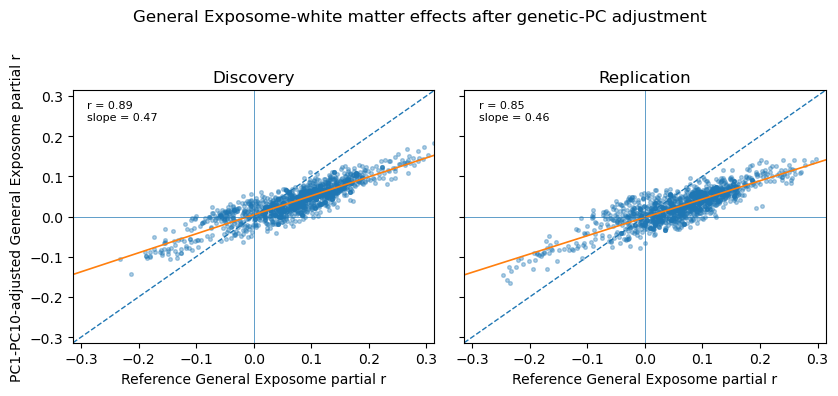

In [8]:
plt.close('all')
gc.collect()

all_vals = []
for split in ['A', 'B']:
    all_vals.append(mu[(split, 'base')]['partial_r'].to_numpy(float))
    all_vals.append(mu[(split, 'pc')]['partial_r'].to_numpy(float))
global_lim = max(np.max(np.abs(v)) for v in all_vals)

fig, axes = plt.subplots(1, 2, figsize=(8.5, 4.0), sharex=True, sharey=True)
for ax, split in zip(axes, ['A', 'B']):
    base = mu[(split, 'base')][['feature', 'partial_r']].rename(columns={'partial_r': 'r_base'})
    pc = mu[(split, 'pc')][['feature', 'partial_r']].rename(columns={'partial_r': 'r_pc'})
    m = base.merge(pc, on='feature', validate='one_to_one')
    x = m['r_base'].to_numpy(float)
    y = m['r_pc'].to_numpy(float)
    r = pearson_r(x, y)
    fit = linregress(x, y)

    ax.scatter(x, y, s=7, alpha=.35, rasterized=True)
    ax.plot([-global_lim, global_lim], [-global_lim, global_lim], '--', linewidth=1)
    xx = np.linspace(-global_lim, global_lim, 100)
    ax.plot(xx, fit.intercept + fit.slope * xx, linewidth=1.2)
    ax.axhline(0, linewidth=.5)
    ax.axvline(0, linewidth=.5)
    ax.set_xlim(-global_lim, global_lim)
    ax.set_ylim(-global_lim, global_lim)
    ax.set_title('Discovery' if split == 'A' else 'Replication')
    ax.set_xlabel('Reference General Exposome partial r')
    ax.text(.04, .96, f'r = {r:.2f}\nslope = {fit.slope:.2f}', transform=ax.transAxes,
            ha='left', va='top', fontsize=8,
            bbox=dict(facecolor='white', edgecolor='none', alpha=.8))
axes[0].set_ylabel('PC1-PC10-adjusted General Exposome partial r')
fig.suptitle('General Exposome-white matter effects after genetic-PC adjustment')
fig.tight_layout(rect=[0, 0, 1, .94])
plot_path = FIG_DIR / 'GeneralExposome_reference_vs_PC_adjustment.png'
fig.savefig(plot_path, dpi=300, bbox_inches='tight')
print('Saved:', plot_path)
plt.show()
plt.close(fig)


Panel statistics:
('A', 'base') {'n': 4029, 'n_fdr': 1113}
('A', 'pc') {'n': 4029, 'n_fdr': 778, 'map_r': np.float64(0.8869689418705821)}
('B', 'base') {'n': 4057, 'n_fdr': 1007}
('B', 'pc') {'n': 4057, 'n_fdr': 656, 'map_r': np.float64(0.8506220737140617)}
Saved: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/figures/reviewer2_genetic_pc/Supplementary_Figure_7_PC_adjustment_heatmap.png
Saved: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/figures/reviewer2_genetic_pc/Supplementary_Figure_7_PC_adjustment_heatmap.svg


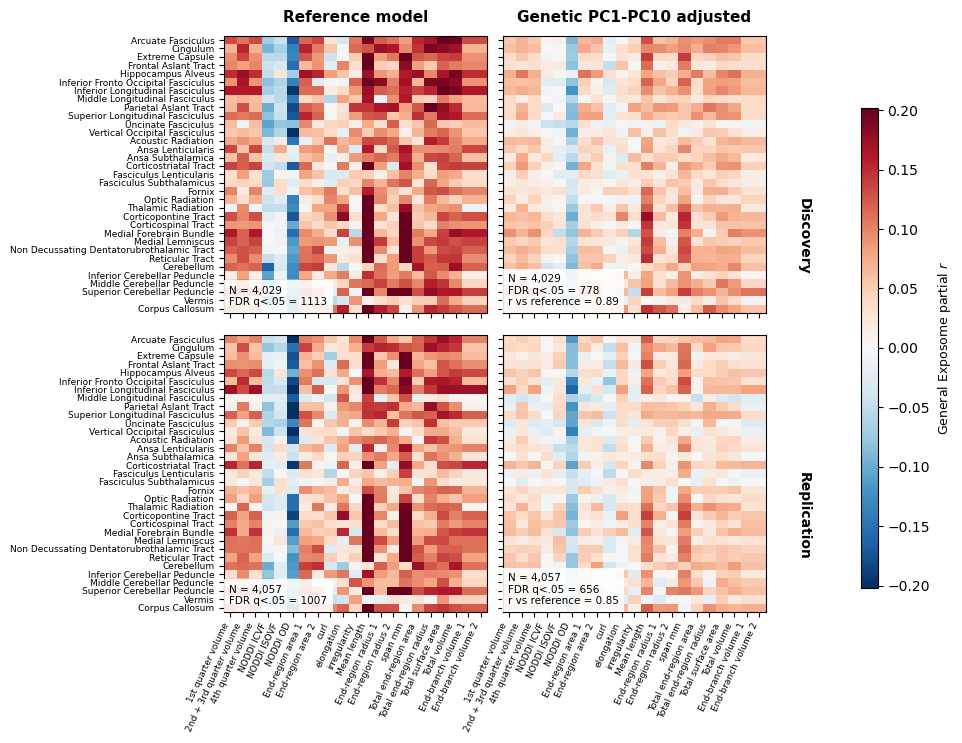

In [9]:
# ============================================================
# Supplementary Figure 7
# Reference vs PC1-PC10-adjusted exposome-WM effect maps
# Discovery and replication samples
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import TwoSlopeNorm
from scipy.stats import pearsonr


# ------------------------------------------------------------
# Figure ordering / labels
# ------------------------------------------------------------
METRIC_ORDER = [
    "1st_quarter_volume_mm3",
    "2nd_and_3rd_quarter_volume_mm3",
    "4th_quarter_volume_mm3",
    "NODDI_icvf",
    "NODDI_isovf",
    "NODDI_od",
    "area_of_end_region_1_mm2",
    "area_of_end_region_2_mm2",
    "curl",
    "elongation",
    "irregularity",
    "mean_length_mm",
    "radius_of_end_region_1_mm",
    "radius_of_end_region_2_mm",
    "span_mm",
    "total_area_of_end_regions_mm2",
    "total_radius_of_end_regions_mm",
    "total_surface_area_mm2",
    "total_volume_mm3",
    "volume_of_end_branches_1",
    "volume_of_end_branches_2"
]

FAMILY_ORDER = {
    "Association": 0,
    "ProjectionBasalGanglia": 1,
    "ProjectionBrainstem": 2,
    "Cerebellum": 3,
    "Commissure": 4
}


def pretty_metric(x):
    labels = {
        "NODDI_icvf": "NODDI ICVF",
        "NODDI_isovf": "NODDI ISOVF",
        "NODDI_od": "NODDI OD",
        "1st_quarter_volume_mm3": "1st quarter volume",
        "2nd_and_3rd_quarter_volume_mm3": "2nd + 3rd quarter volume",
        "4th_quarter_volume_mm3": "4th quarter volume",
        "area_of_end_region_1_mm2": "End-region area 1",
        "area_of_end_region_2_mm2": "End-region area 2",
        "radius_of_end_region_1_mm": "End-region radius 1",
        "radius_of_end_region_2_mm": "End-region radius 2",
        "total_area_of_end_regions_mm2": "Total end-region area",
        "total_radius_of_end_regions_mm": "Total end-region radius",
        "total_surface_area_mm2": "Total surface area",
        "total_volume_mm3": "Total volume",
        "mean_length_mm": "Mean length",
        "volume_of_end_branches_1": "End-branch volume 1",
        "volume_of_end_branches_2": "End-branch volume 2",
    }
    return labels.get(x, x.replace("_", " "))


def camel_spaces(x):
    return re.sub(r"(?<!^)(?=[A-Z])", " ", str(x)).strip()


# ------------------------------------------------------------
# Average homologous L/R effects for visualization
# ------------------------------------------------------------
def parse_results(df):
    rows = []

    for feature, r in zip(df["feature"], df["partial_r"]):
        feature = str(feature)

        if feature.endswith("_median"):
            feature = feature[:-len("_median")]

        if not feature.startswith("bundle_"):
            continue

        parts = feature[len("bundle_"):].split("_")

        if len(parts) < 3:
            continue

        family, tract_hemi = parts[0], parts[1]
        metric = "_".join(parts[2:])

        if metric not in METRIC_ORDER:
            continue

        # Remove hemisphere suffix so L/R homologues are averaged
        tract = re.sub(r"(L|R)$", "", tract_hemi)

        rows.append(
            (
                family,
                f"{family}::{tract}",
                camel_spaces(tract),
                metric,
                float(r),
            )
        )

    out = pd.DataFrame(
        rows,
        columns=[
            "family",
            "tract_key",
            "tract_label",
            "metric",
            "partial_r",
        ],
    )

    return (
        out.groupby(
            ["family", "tract_key", "tract_label", "metric"],
            as_index=False,
        )["partial_r"]
        .mean()
    )


# ------------------------------------------------------------
# Parse reference and PC-adjusted results
# ------------------------------------------------------------
parsed = {
    (split, model): parse_results(mu[(split, model)])
    for split in ["A", "B"]
    for model in ["base", "pc"]
}


# ------------------------------------------------------------
# Define tract ordering
# ------------------------------------------------------------
tract_info = pd.concat(
    [
        parsed[("A", "base")][["family", "tract_key", "tract_label"]],
        parsed[("B", "base")][["family", "tract_key", "tract_label"]],
    ],
    ignore_index=True,
).drop_duplicates()

tract_info["family_order"] = (
    tract_info["family"]
    .map(FAMILY_ORDER)
    .fillna(99)
)

tract_info = (
    tract_info
    .sort_values(["family_order", "tract_label"])
    .reset_index(drop=True)
)

TRACT_ORDER = tract_info["tract_key"].tolist()
TRACT_LABELS = tract_info["tract_label"].tolist()


def make_matrix(df):
    return (
        df.pivot(
            index="tract_key",
            columns="metric",
            values="partial_r",
        )
        .reindex(
            index=TRACT_ORDER,
            columns=METRIC_ORDER,
        )
    )


mats = {
    (split, model): make_matrix(parsed[(split, model)])
    for split in ["A", "B"]
    for model in ["base", "pc"]
}


# ------------------------------------------------------------
# Common color scale across all four panels
# ------------------------------------------------------------
vals = np.concatenate(
    [
        m.to_numpy().ravel()
        for m in mats.values()
    ]
)

vals = vals[np.isfinite(vals)]

vmax = np.nanpercentile(np.abs(vals), 98)

norm = TwoSlopeNorm(
    vmin=-vmax,
    vcenter=0,
    vmax=vmax,
)


# ------------------------------------------------------------
# Panel statistics
# ------------------------------------------------------------
panel_stats = {}

for split in ["A", "B"]:

    base = mu[(split, "base")]
    pc = mu[(split, "pc")]

    n = len(analysis_dfs[split])

    # Reference panel
    panel_stats[(split, "base")] = {
        "n": n,
        "n_fdr": int((base["p_fdr"] < .05).sum()),
    }

    # Compare PC-adjusted map with reference map
    comp = (
        base[["feature", "partial_r"]]
        .rename(columns={"partial_r": "r_base"})
        .merge(
            pc[["feature", "partial_r"]]
            .rename(columns={"partial_r": "r_pc"}),
            on="feature",
            validate="one_to_one",
        )
    )

    map_r = pearsonr(
        comp["r_base"],
        comp["r_pc"],
    )[0]

    panel_stats[(split, "pc")] = {
        "n": n,
        "n_fdr": int((pc["p_fdr"] < .05).sum()),
        "map_r": map_r,
    }


print("Panel statistics:")
for key, value in panel_stats.items():
    print(key, value)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, axes = plt.subplots(
    2,
    2,
    figsize=(9.5, 8),
    sharex=True,
    sharey=True,
)


# Column titles
axes[0, 0].set_title(
    "Reference model",
    fontsize=11,
    fontweight="bold",
    pad=10,
)

axes[0, 1].set_title(
    "Genetic PC1-PC10 adjusted",
    fontsize=11,
    fontweight="bold",
    pad=10,
)


for row, split in enumerate(["A", "B"]):

    for col, model in enumerate(["base", "pc"]):

        ax = axes[row, col]

        im = ax.imshow(
            mats[(split, model)].to_numpy(),
            aspect="auto",
            cmap="RdBu_r",
            norm=norm,
            interpolation="nearest",
        )

        s = panel_stats[(split, model)]

        text = (
            f"N = {s['n']:,}\n"
            f"FDR q<.05 = {s['n_fdr']}"
        )

        if model == "pc":
            text += (
                f"\nr vs reference = "
                f"{s['map_r']:.2f}"
            )

        ax.text(
            .02,
            .02,
            text,
            transform=ax.transAxes,
            fontsize=7.5,
            ha="left",
            va="bottom",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=.88,
            ),
        )


# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------
metric_labels = [
    pretty_metric(x)
    for x in METRIC_ORDER
]

for ax in axes[-1, :]:
    ax.set_xticks(
        np.arange(len(METRIC_ORDER))
    )
    ax.set_xticklabels(
        metric_labels,
        rotation=65,
        ha="right",
        fontsize=6.5,
    )


# Tract names only on first column
for row in range(2):
    axes[row, 0].set_yticks(
        np.arange(len(TRACT_ORDER))
    )
    axes[row, 0].set_yticklabels(
        TRACT_LABELS,
        fontsize=6.5,
    )

for ax in axes[:, 1]:
    ax.tick_params(
        axis="y",
        labelleft=False,
    )


# ------------------------------------------------------------
# Discovery / Replication labels
# ------------------------------------------------------------
fig.text(
    .84,
    .66,
    "Discovery",
    rotation=270,
    va="center",
    ha="center",
    fontsize=10,
    fontweight="bold",
)

fig.text(
    .84,
    .31,
    "Replication",
    rotation=270,
    va="center",
    ha="center",
    fontsize=10,
    fontweight="bold",
)


# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------
cbar_ax = fig.add_axes(
    [.90, .22, .018, .60]
)

cbar = fig.colorbar(
    im,
    cax=cbar_ax,
)

cbar.set_label(
    r"General Exposome partial $r$",
    fontsize=9,
)


# ------------------------------------------------------------
# Layout / save
# ------------------------------------------------------------
fig.subplots_adjust(
    left=.23,
    right=.80,
    bottom=.19,
    top=.91,
    wspace=.06,
    hspace=.08,
)

out_png = (
    FIG_DIR /
    "Supplementary_Figure_7_PC_adjustment_heatmap.png"
)

out_svg = (
    FIG_DIR /
    "Supplementary_Figure_7_PC_adjustment_heatmap.svg"
)

fig.savefig(
    out_png,
    dpi=600,
    bbox_inches="tight",
    pad_inches=.08,
)

fig.savefig(
    out_svg,
    bbox_inches="tight",
    pad_inches=.08,
)

print("Saved:", out_png)
print("Saved:", out_svg)

plt.show()
plt.close(fig)